# Land subsidence forecast: Venice (8 EGMS points)

**Data (Venice, plus any other city's workbook you add to `DATA_FILE`):** Copernicus European Ground Motion Service (EGMS) vertical displacement (mm) at 8 points in Venice, every ~6 days, Dec 2020 – Nov 2025. Negative = moving **down**. Already processed from Sentinel-1 radar (InSAR), so no image processing needed.

**Method, for each point separately** (as the data handover asks):

1. Fit a **trend + yearly cycle** model by least squares (regression):
$$d(t) = a + v\,t + c\cos(2\pi t) + s\sin(2\pi t)$$
   - *v* = **subsidence velocity** in mm/year (the key number),
   - the cos/sin terms = a yearly up-down wobble (thermal expansion and groundwater; EGMS calls it "seasonality").
2. Also try adding **acceleration** (½·*acc*·*t²*): is sinking speeding up?
3. **Backtest:** hide the last 12 months, refit, forecast them, and compare with a naive baseline ("stays at its last value"). Keep the acceleration term only if it forecasts better.
4. **Forecast** 24 months ahead with a 95% range. Residuals of displacement data are correlated in time, so the range is widened accordingly (otherwise it would be falsely narrow).
5. **Flag** unusual readings (robust z-score of the residuals), e.g. sudden dips.
6. **Check** our velocity against EGMS's own published velocity (used only as a check, never as an input).

Output: `subsidence_forecast.json` for the website.

## Settings

In [1]:
DATA_FILE   = ["Italy_Multi_Hazard_SAR_Flood_Forest_Subsidence_2019_2026.xlsx",   # list of workbooks
               "London_Multi_Hazard_SAR_Flood_Forest_Subsidence_2019_2026_With_Coordinates.xlsx"]
COLUMN_ALIASES = {"latitude_wgs84": "latitude", "longitude_wgs84": "longitude"}   # London's names -> standard names
SHEET       = "Land Subsidence"
POINT_COL, DATE_COL, VALUE_COL = "point_id", "date", "vertical_displacement_mm"
HORIZON_MONTHS = 24          # how far ahead to forecast
BACKTEST_MONTHS = 12         # how much recent data to hide when testing
Z_FLAG = 5                   # robust z above this = flagged reading
OUTPUT_FILE = "subsidence_forecast.json"
LABEL = "Vertical displacement (mm), forecast; negative = downward"

In [2]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 3.5)

files = DATA_FILE if isinstance(DATA_FILE, list) else [DATA_FILE]
def read_one(f):
    df = pd.read_excel(f, sheet_name=SHEET).rename(columns=COLUMN_ALIASES)
    if "city" not in df.columns:                       # e.g. London's file: take the city from the file name
        df["city"] = str(f).split("/")[-1].split("_")[0]
    return df
raw = pd.concat([read_one(f) for f in files], ignore_index=True)
raw[DATE_COL] = pd.to_datetime(raw[DATE_COL])
raw = raw.sort_values([POINT_COL, DATE_COL])
dupes = raw.duplicated([POINT_COL, DATE_COL]).sum()
raw = raw.groupby([POINT_COL, DATE_COL], as_index=False).agg({VALUE_COL: "mean", **{c: "first" for c in raw.columns
                                                              if c not in (POINT_COL, DATE_COL, VALUE_COL)}})
print(raw.shape, "| points:", raw[POINT_COL].nunique(), "| duplicate point-dates averaged:", int(dupes))
print(raw.groupby(POINT_COL)[DATE_COL].agg(["min", "max", "count"]))

(4840, 15) | points: 16 | duplicate point-dates averaged: 0
                  min        max  count
point_id                               
10UH4bzuBv 2020-12-09 2025-11-25    303
10UHIfzdmV 2020-12-09 2025-11-25    303
10UHknz6we 2020-12-09 2025-11-25    303
10UHpUeM8O 2020-12-09 2025-11-25    303
10UHpUeM8p 2020-12-09 2025-11-25    303
10UHuBJbKk 2020-12-09 2025-11-25    303
10UIHcdpJ2 2020-12-09 2025-11-25    303
10UIaNIo5E 2020-12-09 2025-11-25    303
40d1upmFqa 2020-12-15 2025-11-25    302
40d24D6kG1 2020-12-15 2025-11-25    302
40d2ReQyEY 2020-12-15 2025-11-25    302
40d339kvkW 2020-12-15 2025-11-25    302
40d4mz3ZFY 2020-12-15 2025-11-25    302
40d69N1yle 2020-12-15 2025-11-25    302
40d6gBgh7E 2020-12-15 2025-11-25    302
40d6pZ1BUl 2020-12-15 2025-11-25    302


## 1. The model

Two versions are fitted for every point:
- **plain trend + yearly cycle**: its slope *v* is the **average velocity** over 2020–2025 (comparable to EGMS's published number),
- **with acceleration**: is the sinking speeding up? Used for the forecast only if it wins the backtest.


`design(t, accel)` builds the regression's input columns. `np.linalg.lstsq` finds the best-fitting coefficients (least squares, same as fitting a line, just with more columns).

**Why widen the range?** Neighbouring readings 6 days apart have similar errors (they're *autocorrelated*), so the data contains less independent information than 303 readings suggests. The standard fix for one lag of correlation ρ multiplies the coefficient uncertainty by √((1+ρ)/(1−ρ)).

In [3]:
def design(t, accel=False):
    cols = [np.ones_like(t), t, np.cos(2 * np.pi * t), np.sin(2 * np.pi * t)]
    if accel:
        cols.append(0.5 * t ** 2)
    return np.column_stack(cols)

def fit(t, y, accel=False):
    X = design(t, accel)
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    sigma2 = resid @ resid / (len(y) - X.shape[1])
    rho = np.corrcoef(resid[:-1], resid[1:])[0, 1] if len(resid) > 2 else 0.0
    rho = float(np.clip(rho, 0, 0.95))
    inflate = (1 + rho) / (1 - rho)                                    # autocorrelation correction
    cov = sigma2 * np.linalg.inv(X.T @ X) * inflate
    return {"beta": beta, "cov": cov, "sigma": np.sqrt(sigma2), "rho": rho, "accel": accel, "resid": resid}

def predict(m, t):
    X = design(t, m["accel"])
    mean = X @ m["beta"]
    se = np.sqrt(m["sigma"] ** 2 + np.einsum("ij,jk,ik->i", X, m["cov"], X))   # noise + coefficient uncertainty
    return mean, mean - 1.96 * se, mean + 1.96 * se

## 2. Backtest each point, choose the model, forecast

For each point: hide the last 12 months → fit (a) trend + yearly cycle, (b) the same plus acceleration → forecast the hidden year → compare mean absolute error (MAE) with the naive "stays at its last value" forecast. **Skill** = 1 − MAE(model)/MAE(naive); positive = better than naive.

In [4]:
meta_cols = [c for c in ["city", "area_label", "country", "latitude", "longitude", "mean_velocity_mm_per_year", "rmse_ts_mm"] if c in raw.columns]
egms_acc, egms_vel = {}, {}                              # EGMS's own published values, for checking only
for f in files:
    try:
        pm = pd.read_excel(f, sheet_name="Point Metadata").set_index("point_id")
        egms_acc.update(pm["acceleration"].to_dict())
        vcol = "mean_velocity_mm_per_year" if "mean_velocity_mm_per_year" in pm else "mean_velocity"
        egms_vel.update(pm[vcol].to_dict())
    except Exception:
        pass
results = {}
for pid, g in raw.groupby(POINT_COL):
    t0 = g[DATE_COL].min()
    t = ((g[DATE_COL] - t0).dt.days / 365.25).to_numpy()
    y = g[VALUE_COL].to_numpy(dtype=float)

    cut = t.max() - BACKTEST_MONTHS / 12
    tr, te = t <= cut, t > cut
    naive_mae = np.mean(np.abs(y[te] - y[tr][-1]))
    bt = {}
    for accel in (False, True):
        m_bt = fit(t[tr], y[tr], accel)
        bt[accel] = np.mean(np.abs(y[te] - predict(m_bt, t[te])[0]))
    use_accel = bt[True] < 0.9 * bt[False]               # acceleration must clearly help, not just fit noise
    m = fit(t, y, use_accel)                             # model used for the FORECAST
    m_lin = fit(t, y, accel=False)                       # plain trend: its slope = AVERAGE velocity over the period
    m_acc = fit(t, y, accel=True)                        # acceleration estimate (reported whichever model is chosen)

    # flags: robust z of residuals
    r = m["resid"]
    mad = np.median(np.abs(r - np.median(r))) * 1.4826
    z = (r - np.median(r)) / (mad if mad > 0 else r.std())

    # forecast monthly from the month after the last reading
    last = g[DATE_COL].max()
    f_dates = pd.date_range(last + pd.offsets.MonthBegin(1), periods=HORIZON_MONTHS, freq="MS")
    f_t = ((f_dates - t0).days / 365.25).to_numpy()
    f_mean, f_lo, f_hi = predict(m, f_t)

    v, v_se = m_lin["beta"][1], np.sqrt(m_lin["cov"][1, 1])
    acc, acc_se = m_acc["beta"][4], np.sqrt(m_acc["cov"][4, 4])
    results[pid] = {"acceleration": (acc, acc_se),"g": g, "t0": t0, "t": t, "y": y, "model": m, "z": z, "f_dates": f_dates,
                    "f": (f_mean, f_lo, f_hi), "velocity": (v, v_se), "use_accel": use_accel,
                    "backtest": {"mae_model": float(bt[use_accel]), "mae_naive": float(naive_mae),
                                 "skill": float(1 - bt[use_accel] / naive_mae) if naive_mae > 0 else None},
                    "meta": g[meta_cols].iloc[0].to_dict()}

rows = []
for pid, r in results.items():
    v, se = r["velocity"]
    rows.append({"point": pid, "city": r["meta"].get("city"), "velocity_mm_yr": round(v, 2), "95% CI": f"{v - 1.96*se:.2f} to {v + 1.96*se:.2f}",
                 "EGMS_velocity": egms_vel.get(pid),
                 "accel_mm_yr2": round(r["acceleration"][0], 2),
                 "EGMS_accel": egms_acc.get(pid),
                 "forecast_uses_accel": r["use_accel"], "backtest_skill": round(r["backtest"]["skill"], 2),
                 "flagged_readings": int((np.abs(r["z"]) > Z_FLAG).sum()),
                 f"forecast_{r['f_dates'][-1]:%Y-%m}_mm": round(r["f"][0][-1], 1)})
summary_table = pd.DataFrame(rows).sort_values("velocity_mm_yr")
summary_table

,point,city,velocity_mm_yr,95% CI,EGMS_velocity,accel_mm_yr2,EGMS_accel,forecast_uses_accel,backtest_skill,flagged_readings,forecast_2027-11_mm
1,10UHIfzdmV,Venice,-3.36,-3.56 to -3.15,-3.4,0.54,0.54,True,0.38,0,-19.3
4,10UHpUeM8p,Venice,-1.70,-1.88 to -1.53,-1.7,-0.26,-0.26,True,0.44,3,-13.7
6,10UIHcdpJ2,Venice,-1.62,-1.77 to -1.47,-1.6,-0.58,-0.58,True,0.44,0,-15.2
7,10UIaNIo5E,Venice,-1.59,-1.69 to -1.49,-1.6,-0.20,-0.20,True,0.32,0,-12.7
0,10UH4bzuBv,Venice,-1.53,-1.63 to -1.42,-1.5,-0.17,-0.17,True,0.56,0,-12.1
5,10UHuBJbKk,Venice,-1.46,-1.58 to -1.34,-1.5,-0.34,-0.34,True,0.64,3,-12.0
3,10UHpUeM8O,Venice,-1.42,-1.53 to -1.31,-1.4,-0.33,-0.33,True,0.49,0,-12.6
2,10UHknz6we,Venice,-1.37,-1.47 to -1.28,-1.4,-0.26,-0.27,True,-0.71,0,-11.0
15,40d6pZ1BUl,London,-1.09,-1.18 to -1.01,-1.1,0.04,0.04,False,0.23,0,-7.3
13,40d69N1yle,London,-1.04,-1.27 to -0.81,-1.0,0.18,0.18,False,-0.35,0,-7.0


## 3. Check against EGMS's published velocity

EGMS publishes its own average velocity and acceleration for each point. We never used them as inputs, so agreement is an **independent sanity check** of our fitting. (Small differences are expected: EGMS fits its own model over its own full time span.)

Velocity, ours minus EGMS: mean +0.00 mm/yr, largest gap 0.05 mm/yr
Acceleration, ours minus EGMS: mean +0.00 mm/yr², largest gap 0.01 mm/yr²
Points where sinking is speeding up (negative acceleration): ours 12 of 16, EGMS 12 of 16


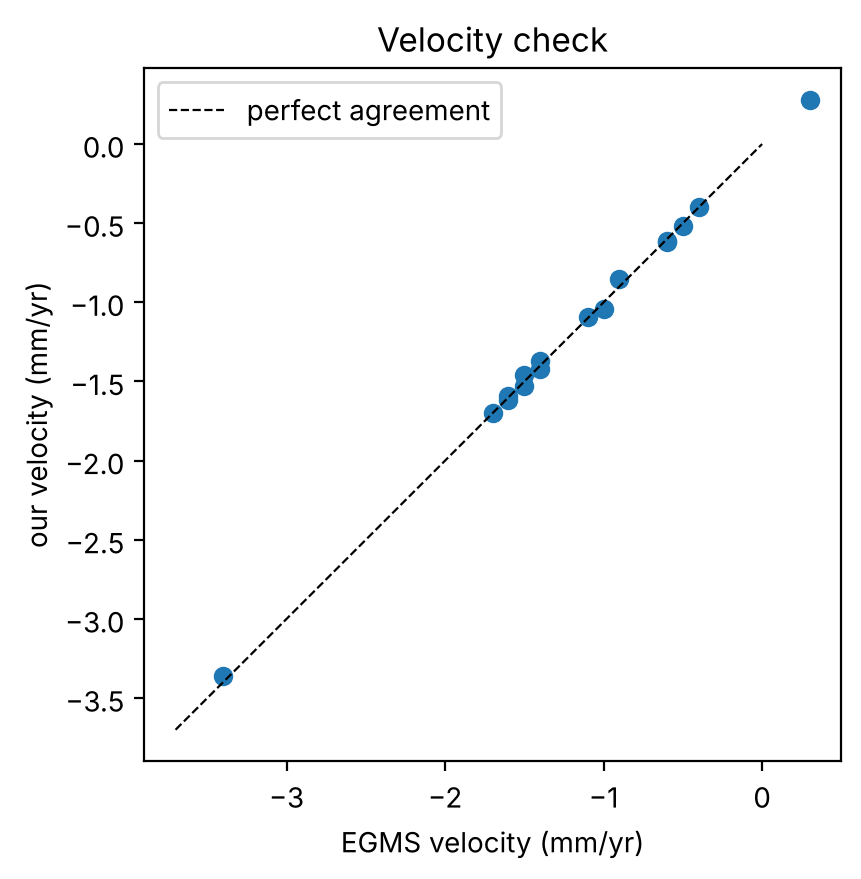

In [5]:
if "EGMS_velocity" in summary_table and summary_table["EGMS_velocity"].notna().all():
    diff = summary_table["velocity_mm_yr"] - summary_table["EGMS_velocity"]
    print(f"Velocity, ours minus EGMS: mean {diff.mean():+.2f} mm/yr, largest gap {diff.abs().max():.2f} mm/yr")
    if summary_table["EGMS_accel"].notna().all():
        da = summary_table["accel_mm_yr2"] - summary_table["EGMS_accel"]
        print(f"Acceleration, ours minus EGMS: mean {da.mean():+.2f} mm/yr², largest gap {da.abs().max():.2f} mm/yr²")
        print(f"Points where sinking is speeding up (negative acceleration): ours {(summary_table['accel_mm_yr2'] < 0).sum()} of {len(summary_table)}, "
              f"EGMS {(summary_table['EGMS_accel'] < 0).sum()} of {len(summary_table)}")
    plt.figure(figsize=(4.5, 4.5))
    plt.scatter(summary_table["EGMS_velocity"], summary_table["velocity_mm_yr"])
    lims = [min(summary_table["EGMS_velocity"].min(), summary_table["velocity_mm_yr"].min()) - 0.3, 0]
    plt.plot(lims, lims, "k--", lw=0.8, label="perfect agreement")
    plt.xlabel("EGMS velocity (mm/yr)"); plt.ylabel("our velocity (mm/yr)"); plt.legend(); plt.title("Velocity check"); plt.show()

## 4. Look at every point

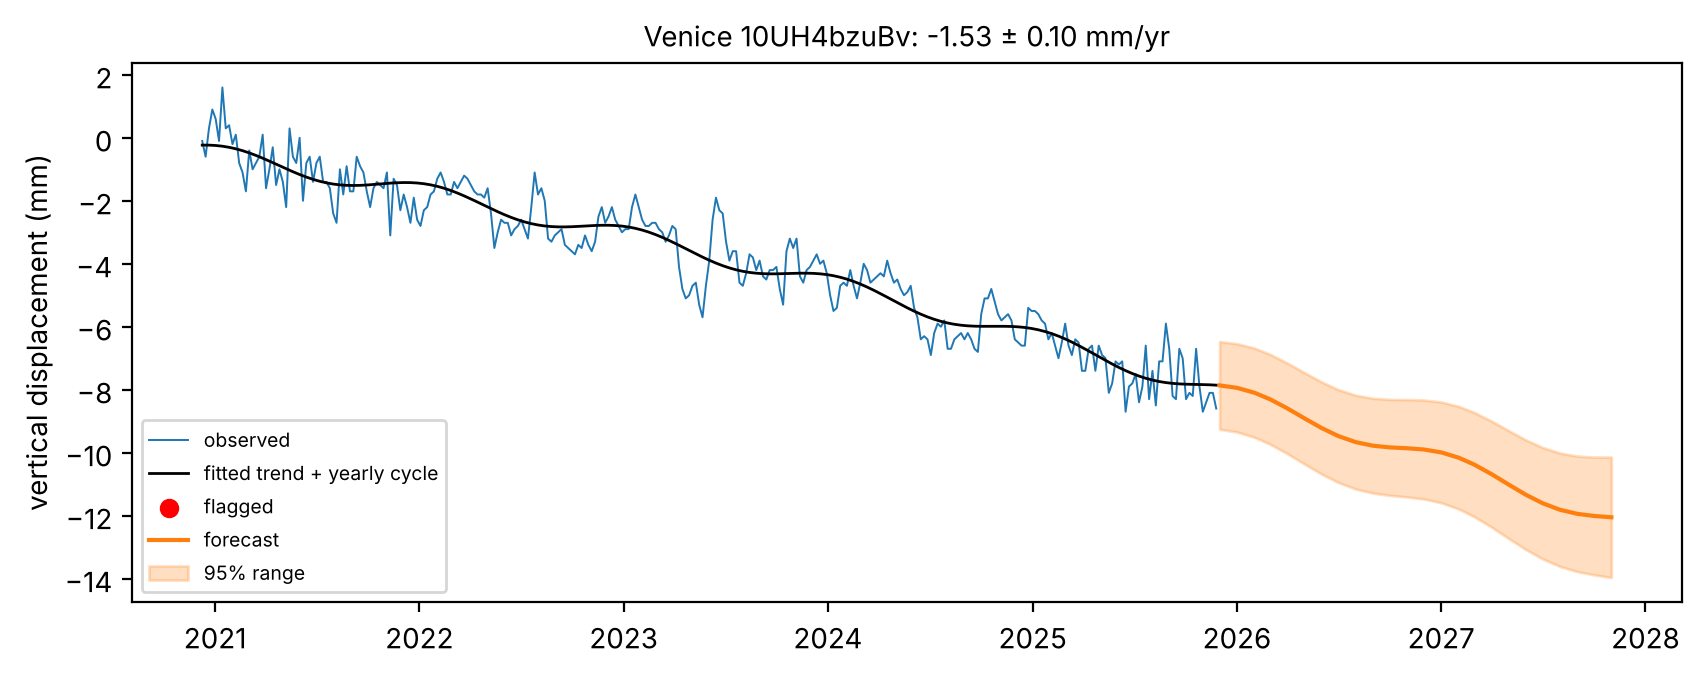

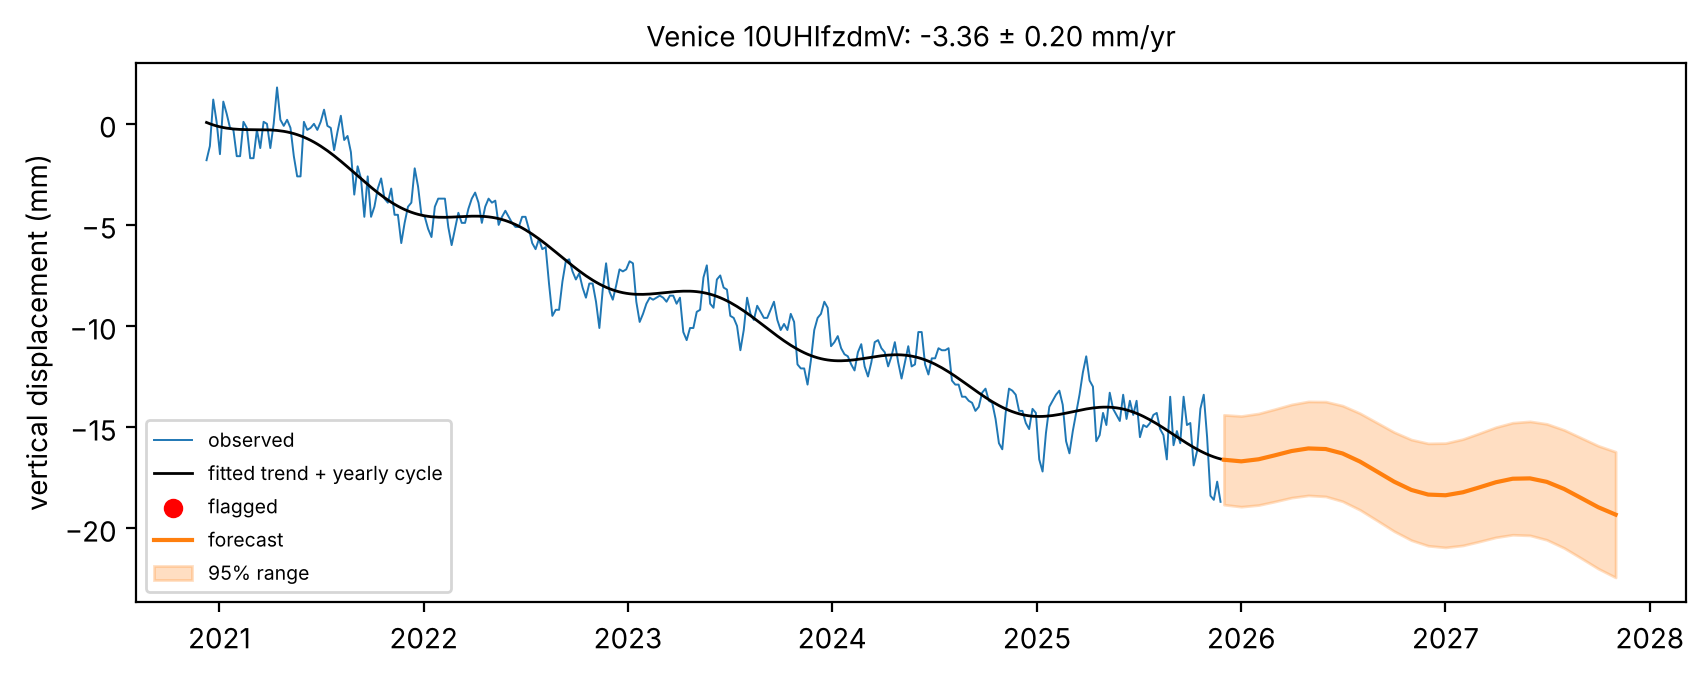

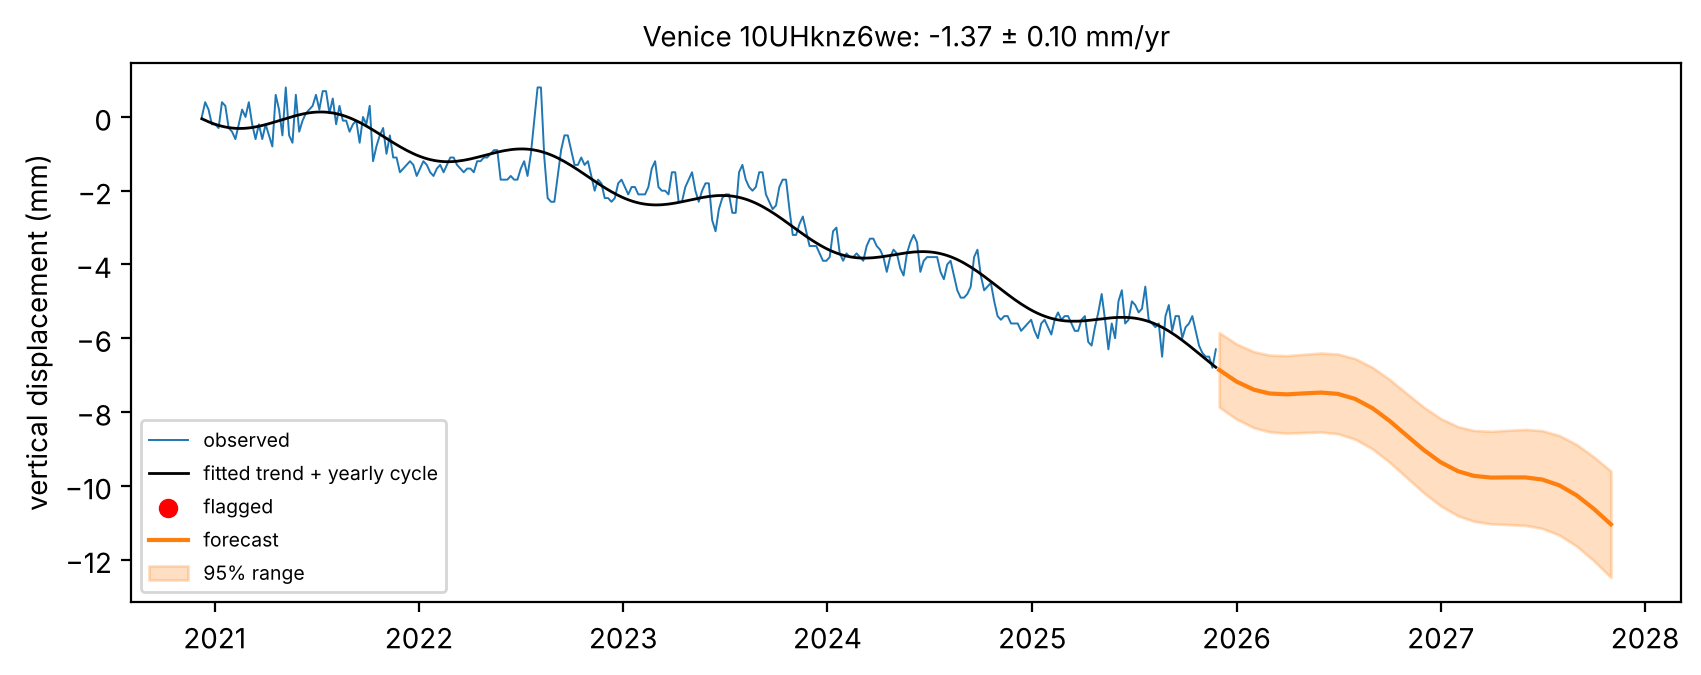

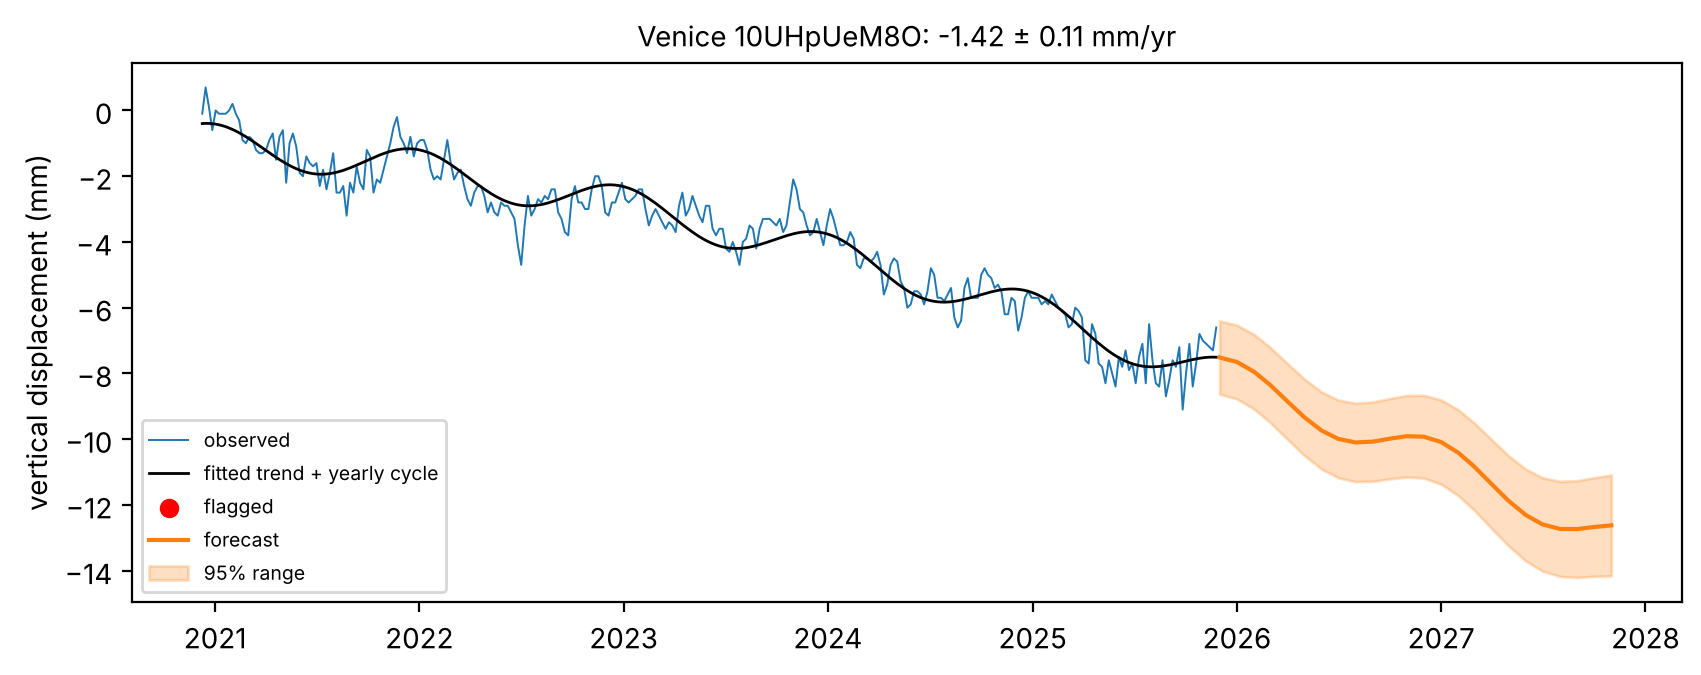

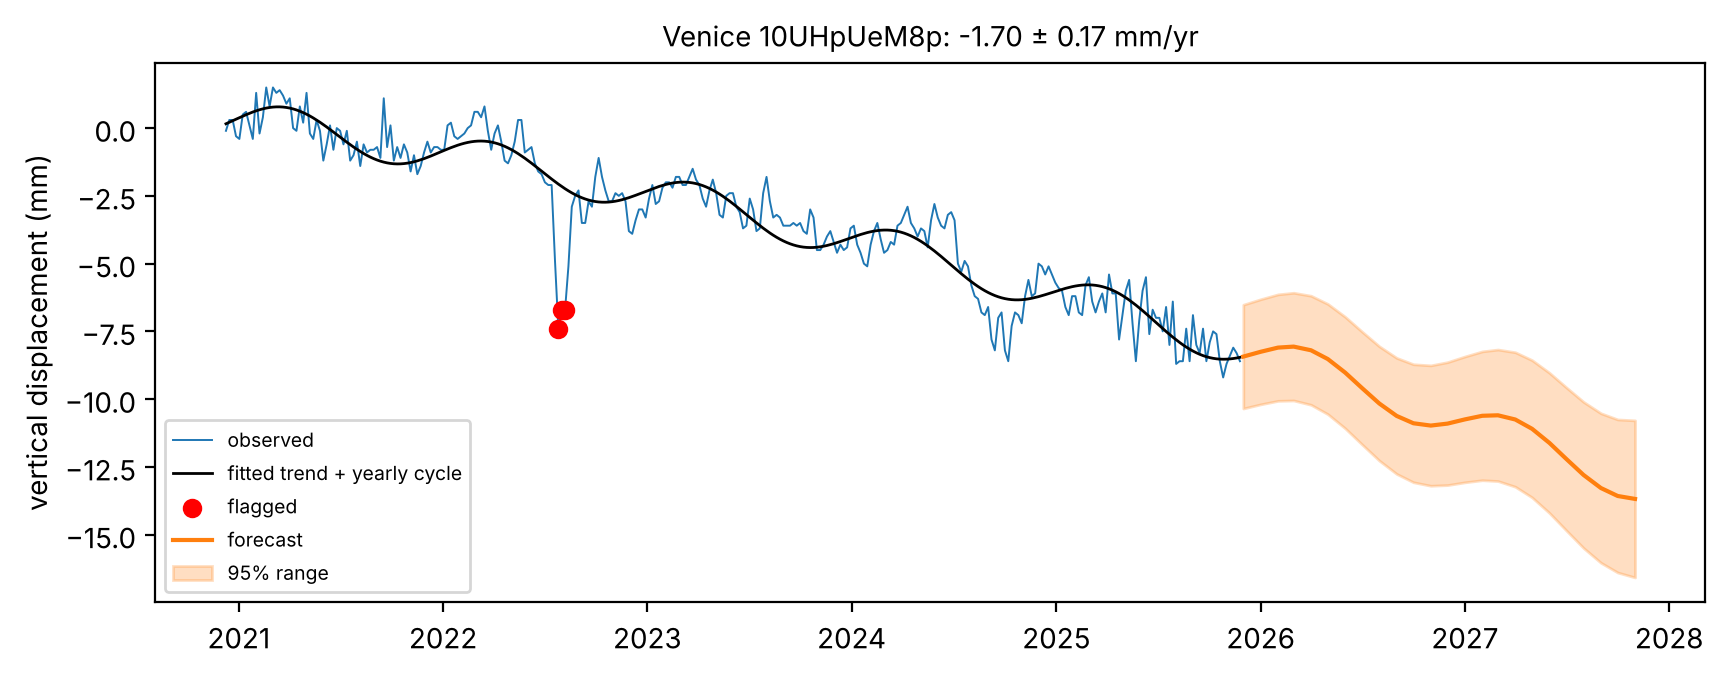

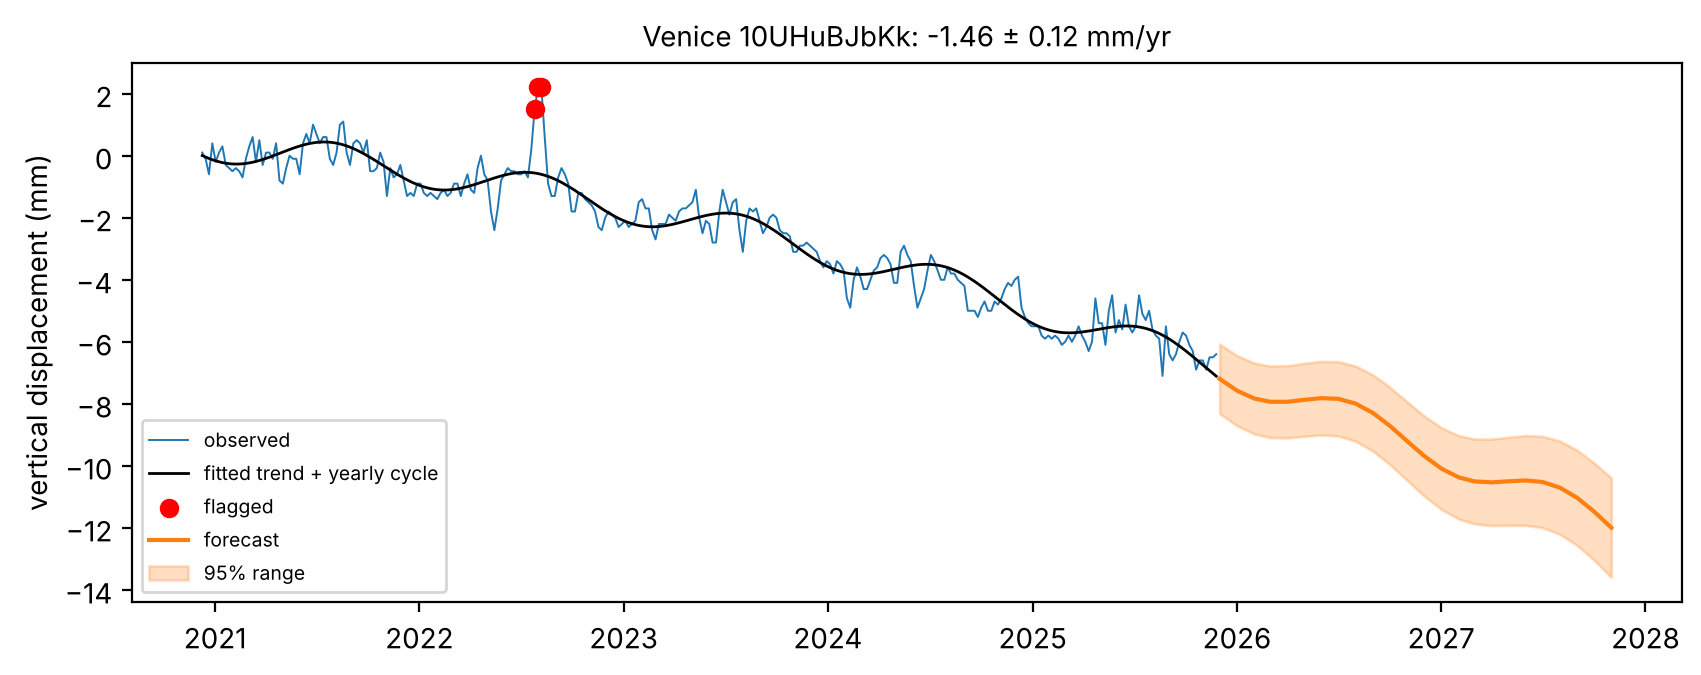

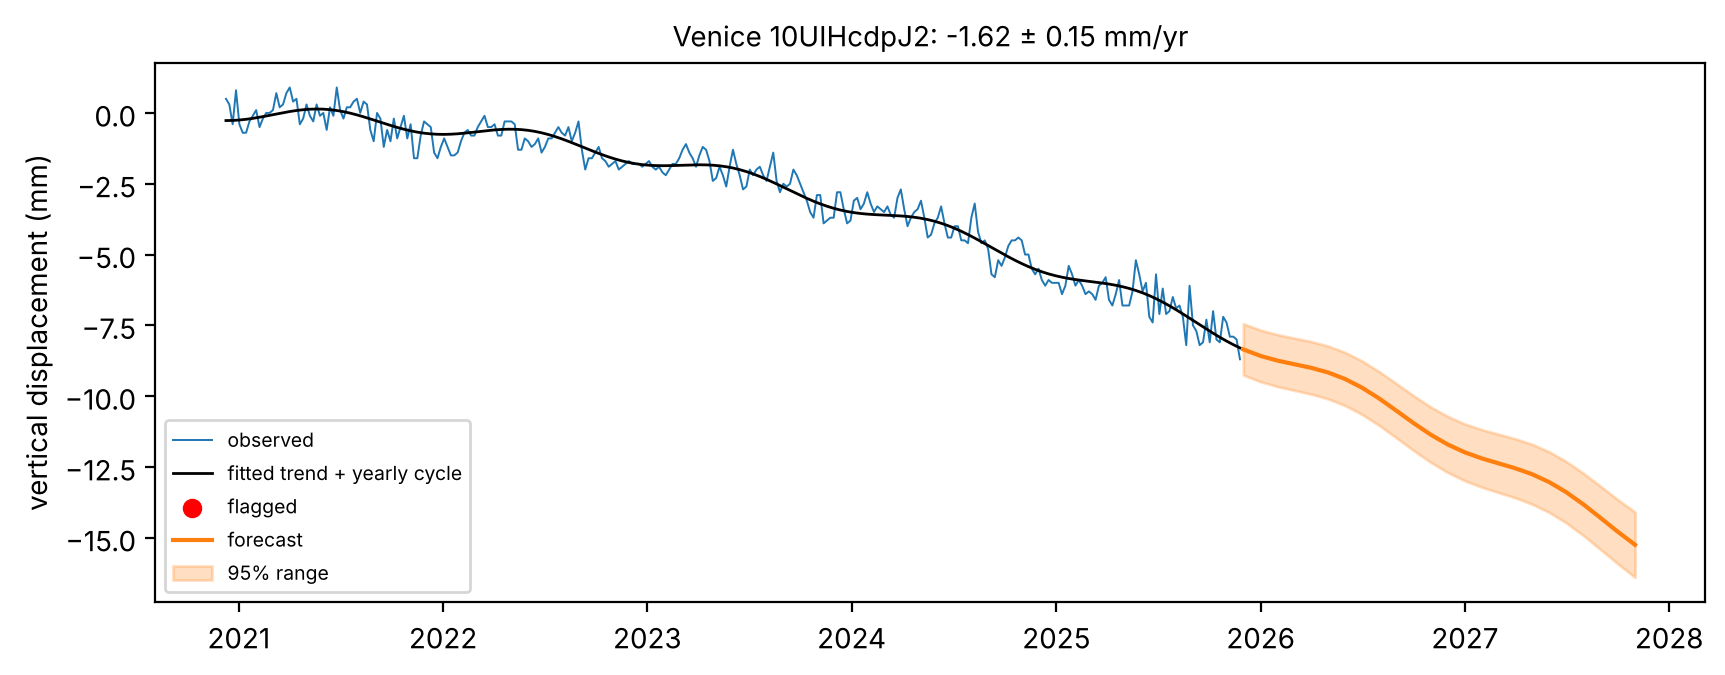

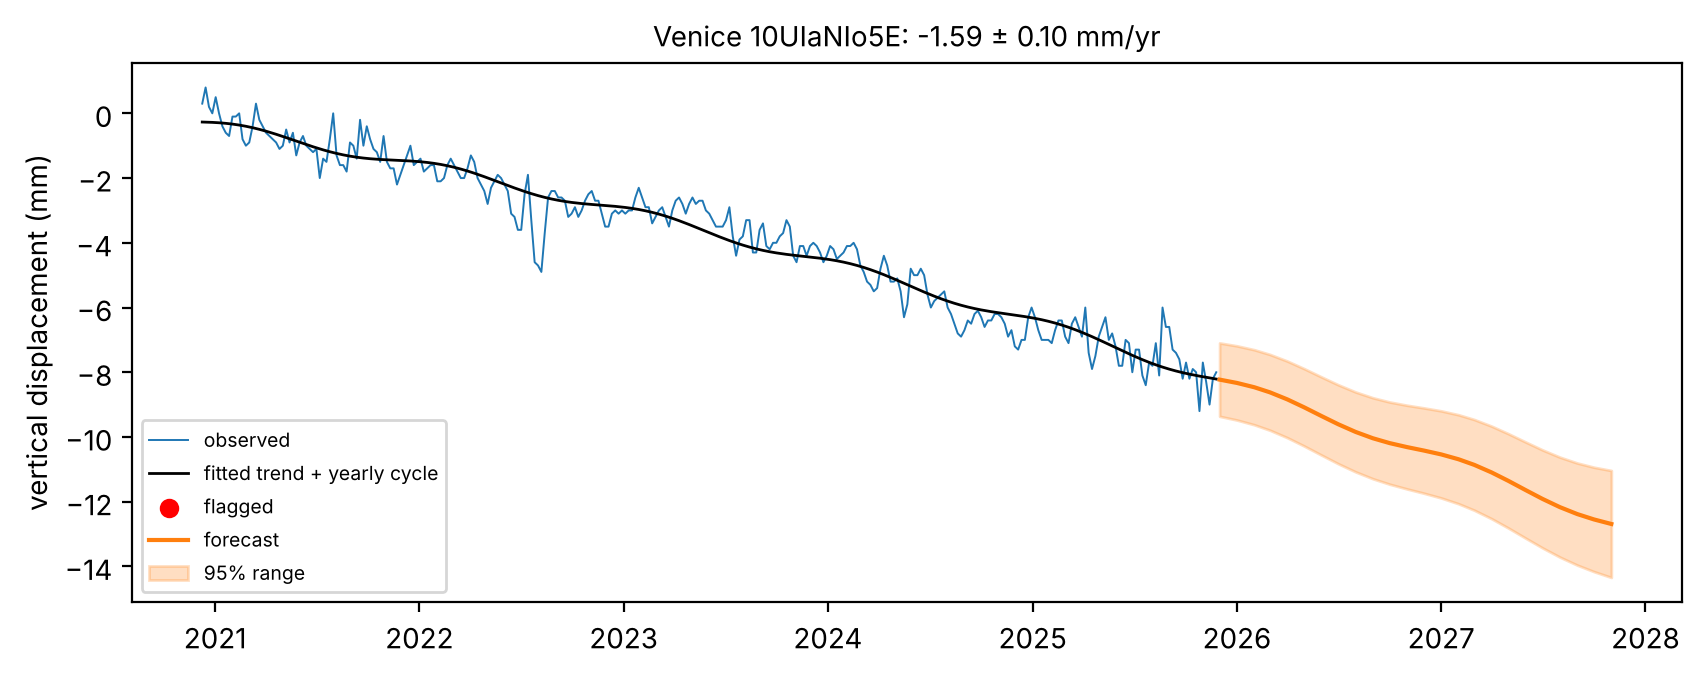

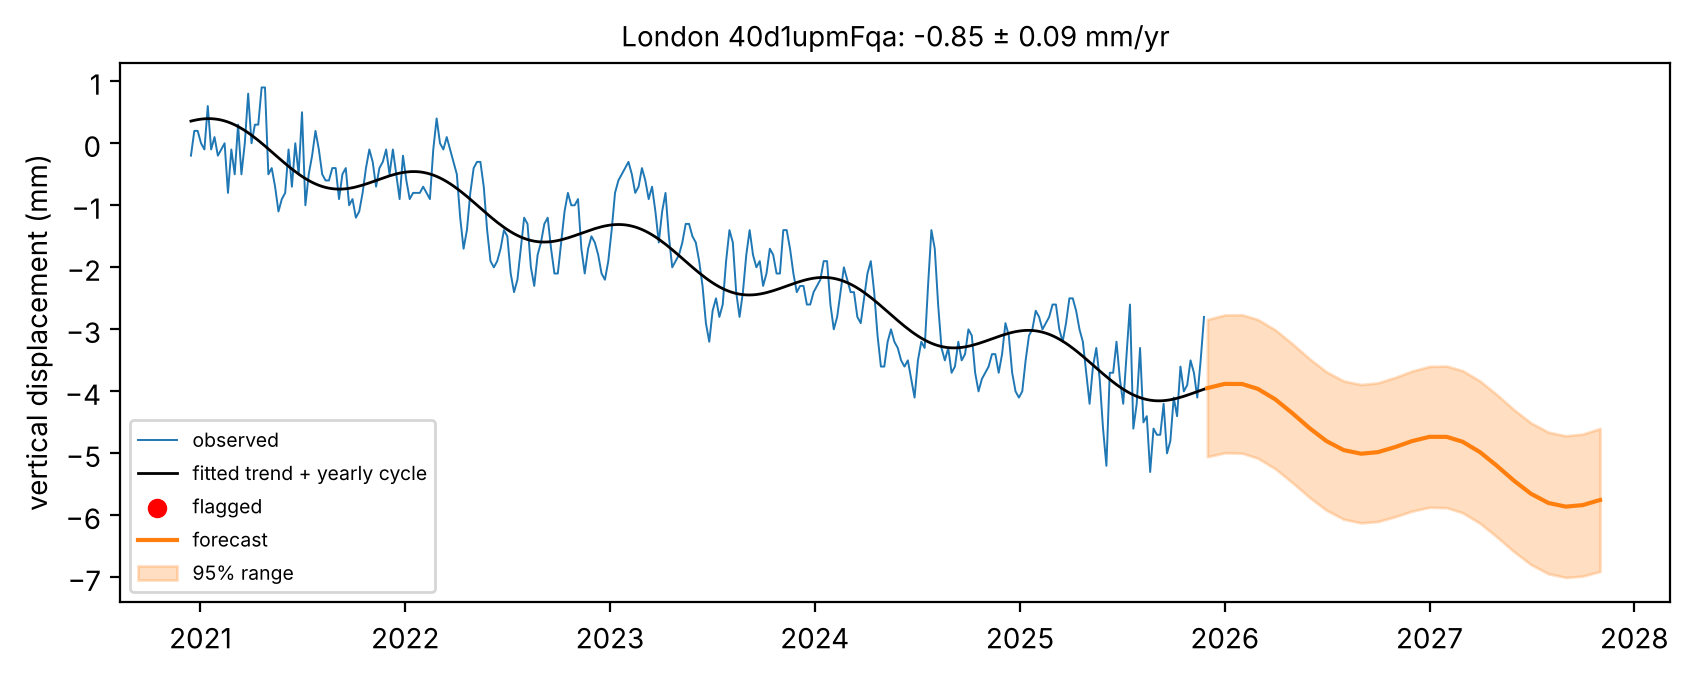

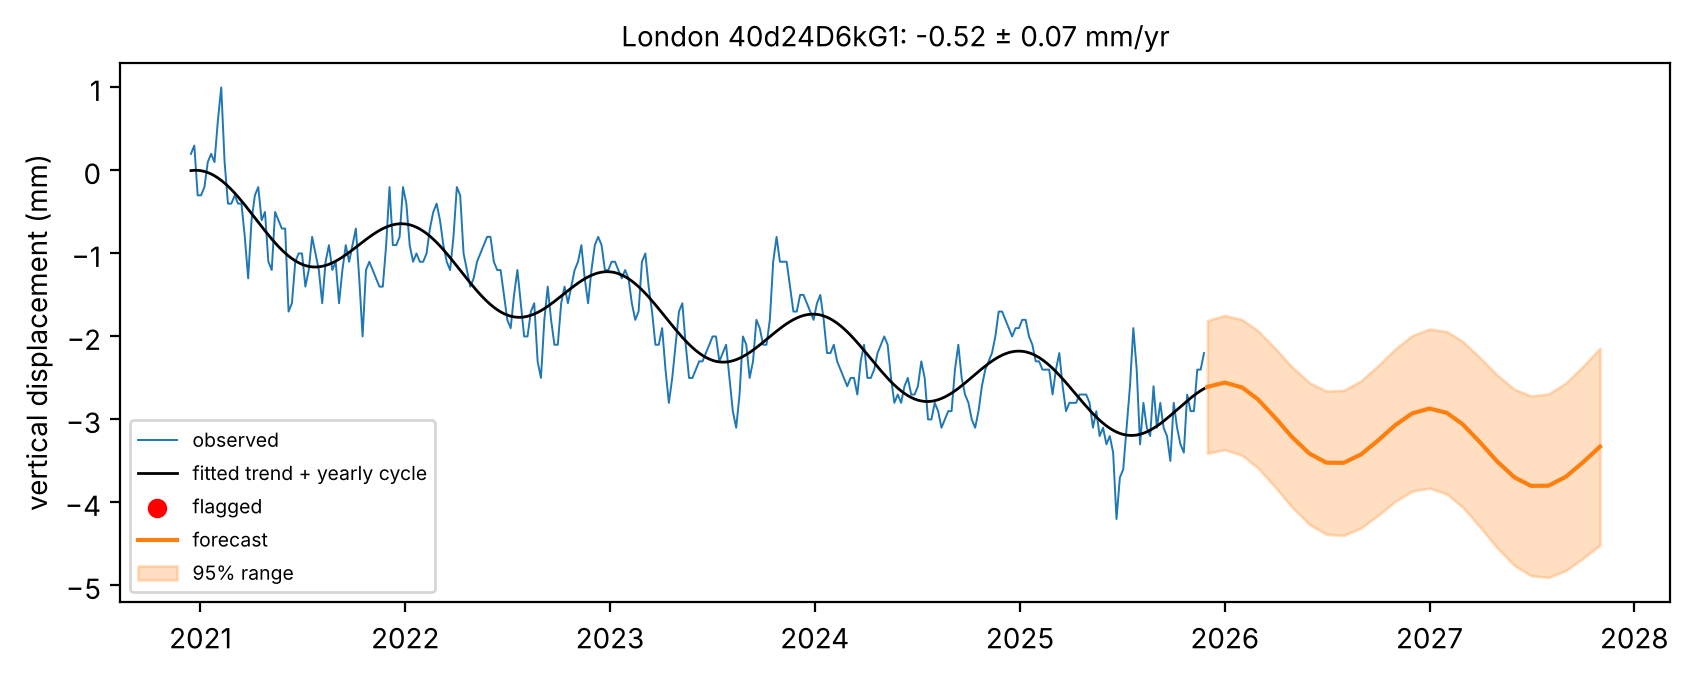

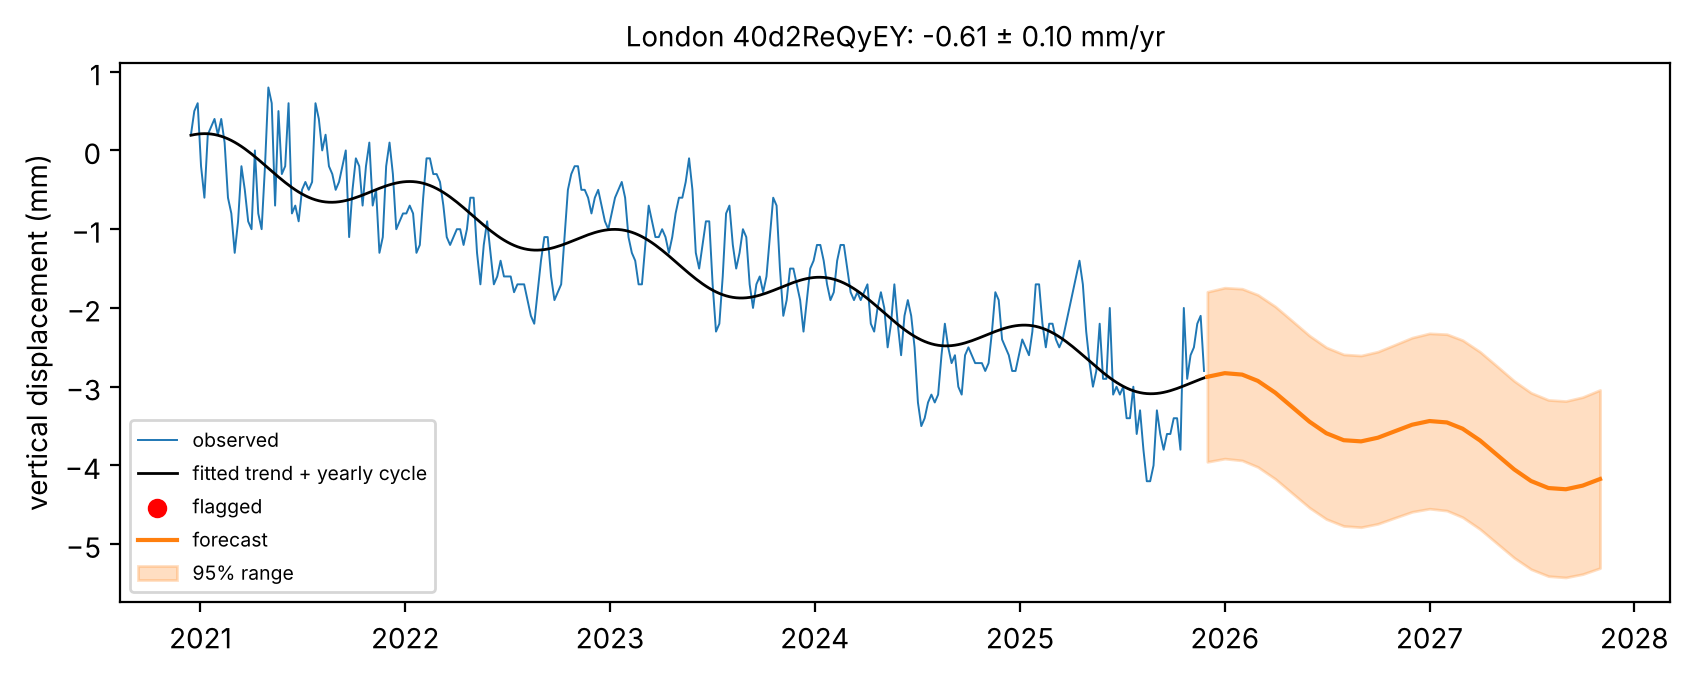

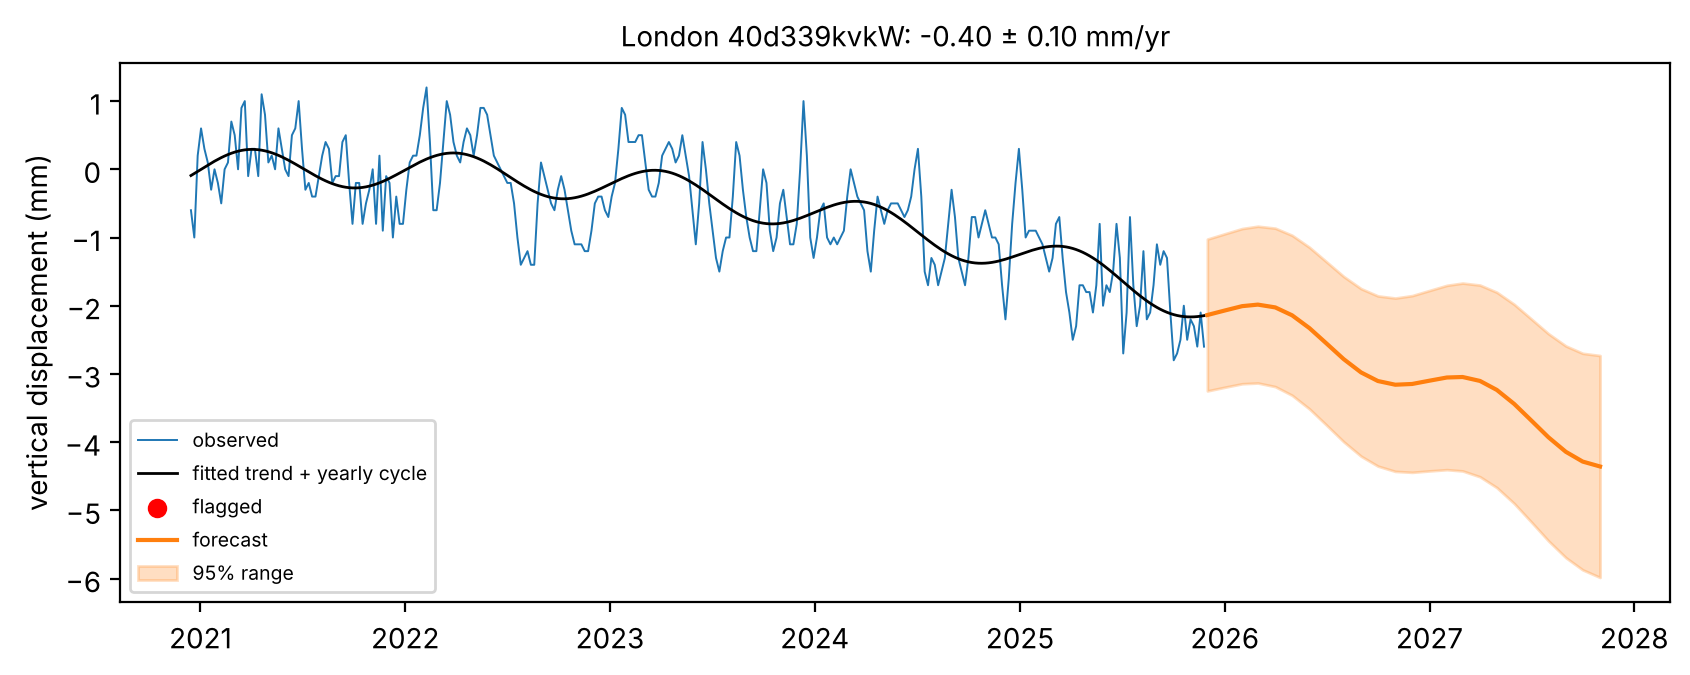

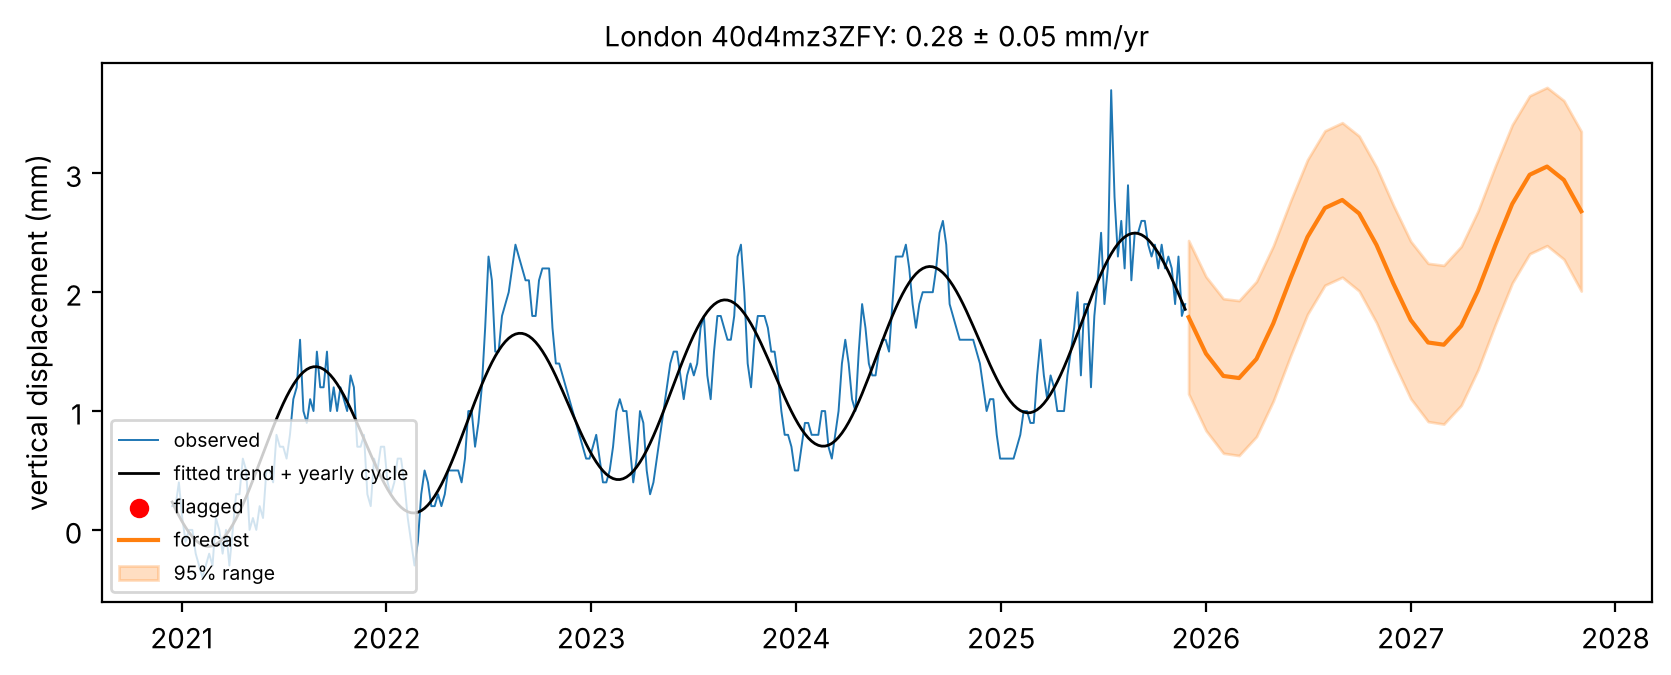

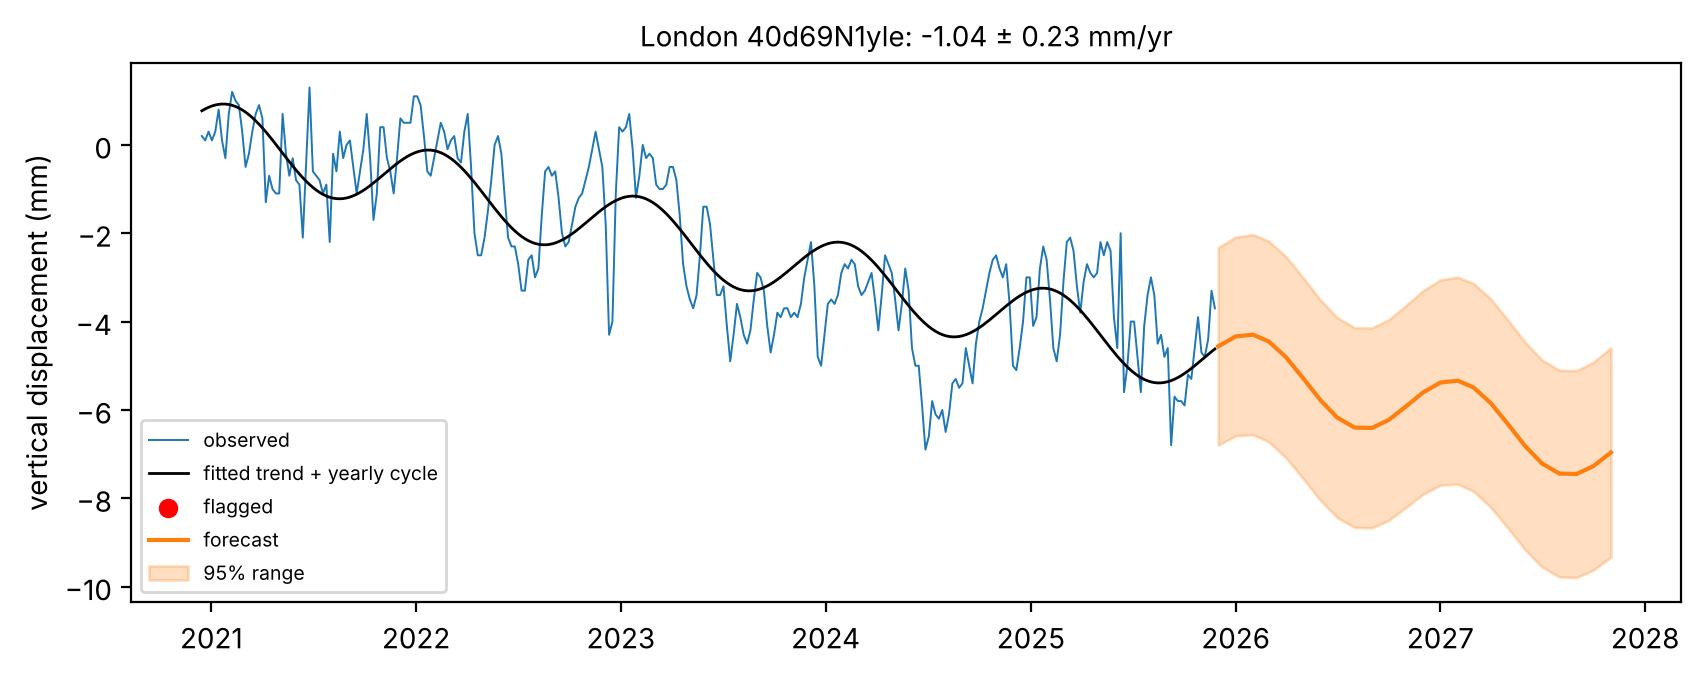

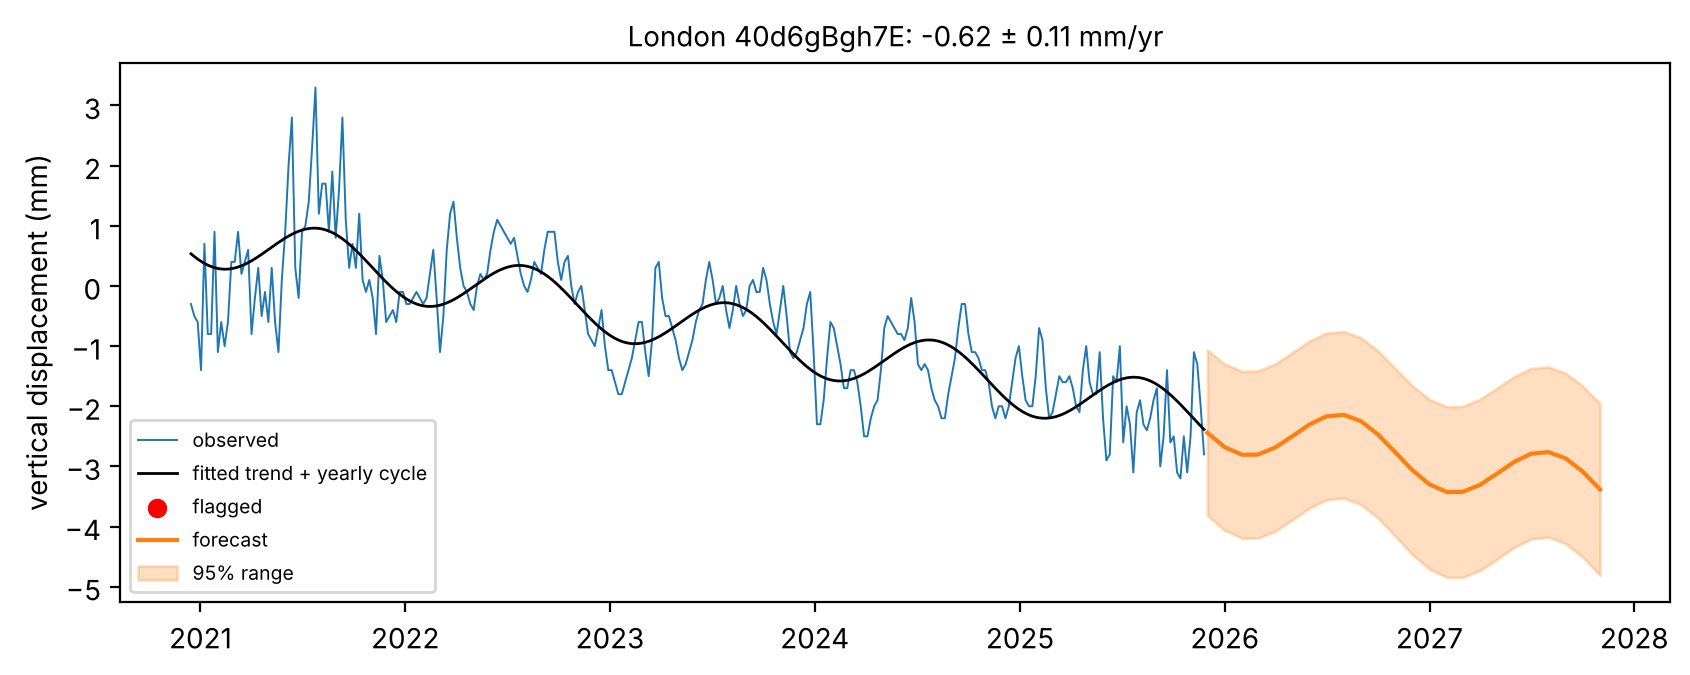

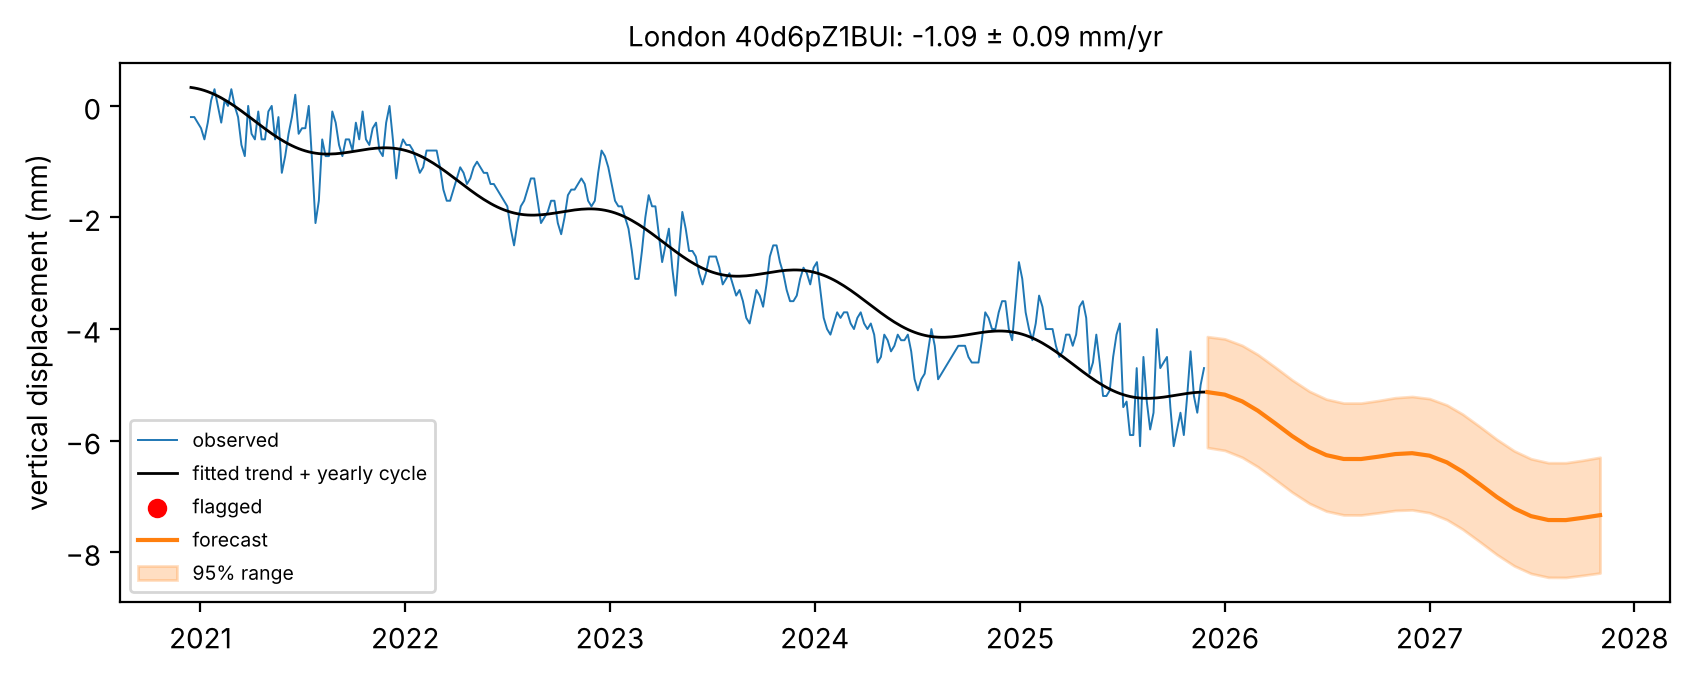

In [6]:
for pid, r in results.items():
    g = r["g"]
    fitted = predict(r["model"], r["t"])[0]
    flagged = np.abs(r["z"]) > Z_FLAG
    plt.plot(g[DATE_COL], r["y"], lw=0.7, label="observed")
    plt.plot(g[DATE_COL], fitted, c="k", lw=1, label="fitted trend + yearly cycle")
    plt.scatter(g[DATE_COL][flagged], r["y"][flagged], c="r", zorder=3, label="flagged")
    f_mean, f_lo, f_hi = r["f"]
    plt.plot(r["f_dates"], f_mean, c="C1", label="forecast")
    plt.fill_between(r["f_dates"], f_lo, f_hi, color="C1", alpha=0.25, label="95% range")
    v, se = r["velocity"]
    plt.title(f"{r['meta'].get('city', '')} {pid}: {v:.2f} ± {1.96*se:.2f} mm/yr", fontsize=10); plt.ylabel("vertical displacement (mm)")
    plt.legend(fontsize=7, loc="lower left"); plt.show()

## 5. Write the JSON for the website

Per point: location, velocity (mm/yr) with 95% CI, model used, backtest, flagged readings, history, and the 24-month forecast with its 95% range.

In [7]:
def r2(x): return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), 2)

out = {"label": LABEL, "units": "mm", "convention": "negative = downward (subsidence)",
       "source": "Copernicus European Ground Motion Service (EGMS), vertical component",
       "caveat": "Selected measurement points, not citywide maps. Forecasts extend past trends; ranges are 95% prediction intervals.",
       "generated": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "points": {}}
for pid, r in results.items():
    v, se = r["velocity"]
    m = r["model"]
    amp = float(np.hypot(m["beta"][2], m["beta"][3]))
    flagged = np.abs(r["z"]) > Z_FLAG
    f_mean, f_lo, f_hi = r["f"]
    out["points"][pid] = {
        "city": r["meta"].get("city"),
        "country": r["meta"].get("country") if isinstance(r["meta"].get("country"), str) else None,
        "location": {"lat": round(float(r["meta"]["latitude"]), 6), "lon": round(float(r["meta"]["longitude"]), 6)}
                    if "latitude" in r["meta"] else None,
        "velocity_mm_per_year": {"estimate": r2(v), "ci95": [r2(v - 1.96 * se), r2(v + 1.96 * se)]},
        "acceleration_mm_per_year2": {"estimate": r2(r["acceleration"][0]),
                                      "ci95": [r2(r["acceleration"][0] - 1.96 * r["acceleration"][1]),
                                               r2(r["acceleration"][0] + 1.96 * r["acceleration"][1])]},
        "egms_published_acceleration": r2(egms_acc.get(pid)),
        "seasonal_amplitude_mm": r2(amp),
        "forecast_model": "trend + yearly cycle" + (" + acceleration" if r["use_accel"] else ""),
        "backtest": {k: r2(v_) for k, v_ in r["backtest"].items()},
        "forecast_confidence": "low (did not beat the naive baseline in backtest)" if (r["backtest"]["skill"] or 0) <= 0 else "normal",
        "egms_published_velocity": r2(egms_vel.get(pid)),
        "area_label": r["meta"].get("area_label") if isinstance(r["meta"].get("area_label"), str) else None,
        "history": [{"date": f"{d:%Y-%m-%d}", "mm": r2(y_), "flagged": bool(f_)}
                    for d, y_, f_ in zip(r["g"][DATE_COL], r["y"], flagged)],
        "forecast": [{"month": f"{d:%Y-%m}", "mean": r2(a), "lower": r2(b), "upper": r2(c)}
                     for d, a, b, c in zip(r["f_dates"], f_mean, f_lo, f_hi)],
    }

with open(OUTPUT_FILE, "w") as f:
    json.dump(out, f, indent=1)
print("Wrote", OUTPUT_FILE, "with", len(out["points"]), "points")

Wrote subsidence_forecast.json with 16 points
